## Assignment no 20

## Monthly Milk Production Forecasting Using RNN, LSTM, and GRU

# Step 1: Identify the Business Problem

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import MinMaxScaler

# Evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

# Deep Learning
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    SimpleRNN,
    LSTM,
    GRU,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

# Date handling
from pandas.tseries.offsets import MonthBegin

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Visualization settings
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


## Step 2: Define the Objective

In [2]:
# Load dataset
df = pd.read_csv('monthly_milk_production.csv')

# Display first five records
print("First Five Records:")
display(df.head())

# Display last five records
print("Last Five Records:")
display(df.tail())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

First Five Records:


,Date,Production
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


Last Five Records:


,Date,Production
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797
167,1975-12,843


Dataset Shape: (168, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Date        168 non-null    object
 1   Production  168 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.8+ KB


In [3]:
# Convert Date column into datetime
df['Date'] = pd.to_datetime(df['Date'])

# Sort dataset chronologically
df = df.sort_values('Date')

# Set Date as index
df.set_index('Date', inplace=True)

# Display dataset
display(df.head())

# Check data types
print(df.dtypes)

# Check date range
print("Start Date:", df.index.min())
print("End Date:", df.index.max())

# Check frequency
print("Number of observations:", len(df))

,Production
Date,
1962-01-01,589
1962-02-01,561
1962-03-01,640
1962-04-01,656
1962-05-01,727


Production    int64
dtype: object
Start Date: 1962-01-01 00:00:00
End Date: 1975-12-01 00:00:00
Number of observations: 168


In [4]:
# Statistical summary
display(df.describe())

,Production
count,168.000000
mean,754.708333
std,102.204524
min,553.000000
25%,677.750000
50%,761.000000
75%,824.500000
max,969.000000


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)

Missing Values:
Production    0
dtype: int64

Missing Value Percentage:
Production    0.0
dtype: float64


In [6]:
# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate dates
print("Duplicate Dates:", df.index.duplicated().sum())

Duplicate Rows: 26
Duplicate Dates: 0


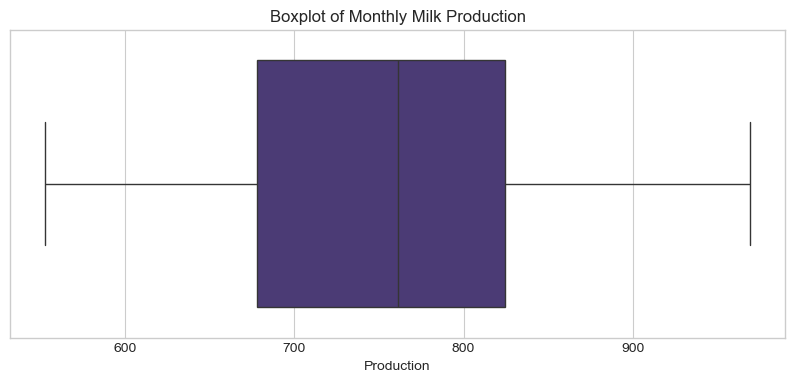

In [7]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Production'])

plt.title('Boxplot of Monthly Milk Production')
plt.xlabel('Production')

plt.show()

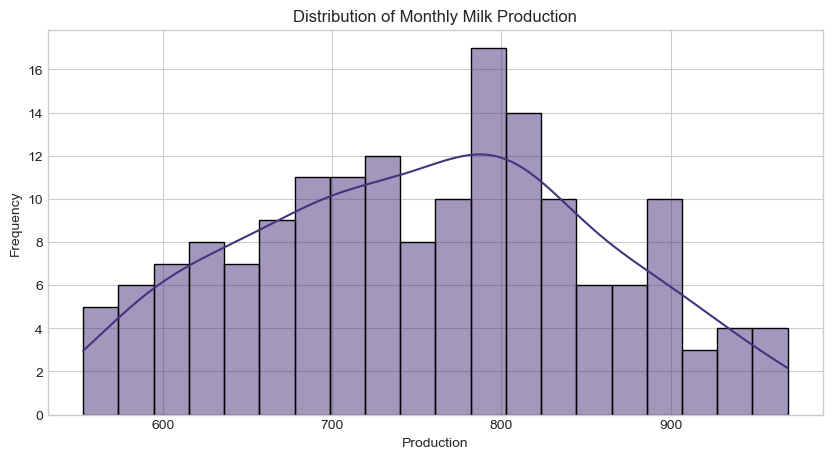

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Production'],
    bins=20,
    kde=True
)

plt.title('Distribution of Monthly Milk Production')
plt.xlabel('Production')
plt.ylabel('Frequency')

plt.show()

Monthly Milk Production Trend

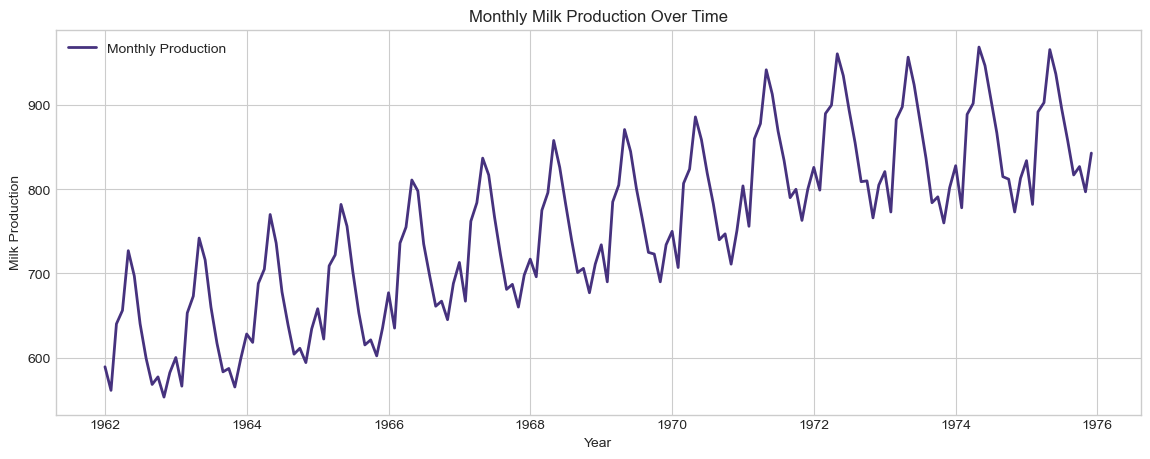

In [9]:
plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df['Production'],
    label='Monthly Production',
    linewidth=2
)

plt.title('Monthly Milk Production Over Time')
plt.xlabel('Year')
plt.ylabel('Milk Production')

plt.legend()
plt.grid(True)
plt.show()

Identify Seasonality

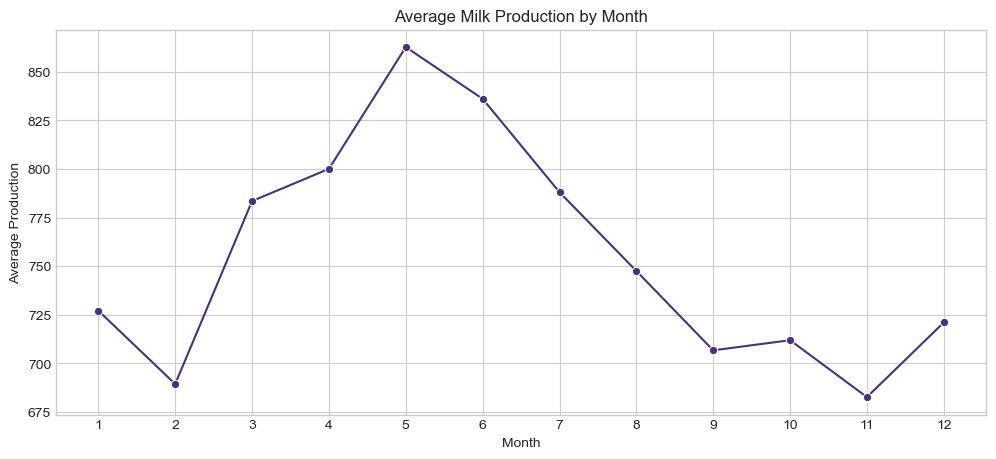

In [10]:
# Extract month and year
df['Month'] = df.index.month
df['Year'] = df.index.year

# Monthly average production
monthly_avg = df.groupby('Month')['Production'].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_avg.index,
    y=monthly_avg.values,
    marker='o'
)

plt.title('Average Milk Production by Month')
plt.xlabel('Month')
plt.ylabel('Average Production')

plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

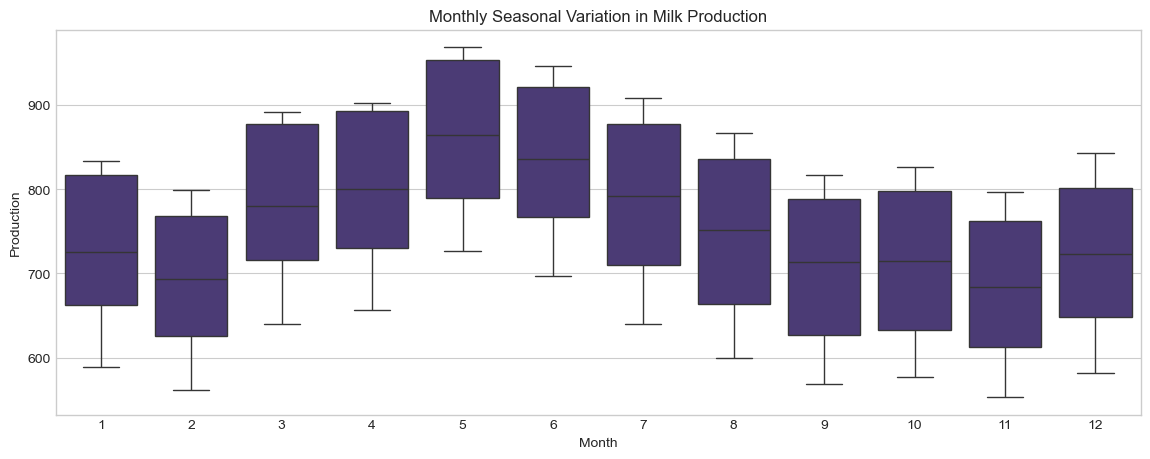

In [ ]:
plt.figure(figsize=(14, 5))

sns.boxplot(
    x='Month',
    y='Production',
    data=df.reset_index()
)

plt.title('Monthly Seasonal Variation in Milk Production')
plt.xlabel('Month')
plt.ylabel('Production')

plt.show()

Rolling Mean Analysis

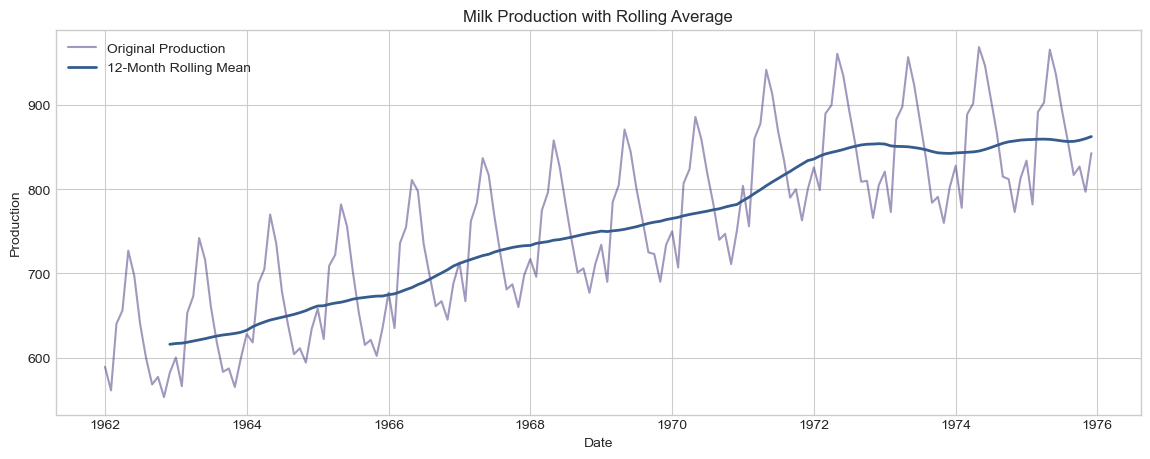

In [12]:
# Calculate 12-month rolling average
df['Rolling_Mean'] = df['Production'].rolling(
    window=12
).mean()

plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df['Production'],
    label='Original Production',
    alpha=0.5
)

plt.plot(
    df.index,
    df['Rolling_Mean'],
    label='12-Month Rolling Mean',
    linewidth=2
)

plt.title('Milk Production with Rolling Average')
plt.xlabel('Date')
plt.ylabel('Production')

plt.legend()
plt.show()

Data Preparation for Deep Learning

Select Production Column

In [13]:
# Create a separate dataframe
data = df[['Production']].copy()

# Display data
display(data.head())

print("Data Shape:", data.shape)

,Production
Date,
1962-01-01,589
1962-02-01,561
1962-03-01,640
1962-04-01,656
1962-05-01,727


Data Shape: (168, 1)


Split Dataset Chronologically

In [14]:
# Total observations
total_size = len(data)

# Calculate split sizes
train_size = int(total_size * 0.70)
val_size = int(total_size * 0.15)

# Split positions
train_end = train_size
val_end = train_size + val_size

# Chronological split
train_data = data.iloc[:train_end]
val_data = data.iloc[train_end:val_end]
test_data = data.iloc[val_end:]

print("Training Size:", len(train_data))
print("Validation Size:", len(val_data))
print("Testing Size:", len(test_data))

print("\nTraining Period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nValidation Period:")
print(val_data.index.min(), "to", val_data.index.max())

print("\nTesting Period:")
print(test_data.index.min(), "to", test_data.index.max())

Training Size: 117
Validation Size: 25
Testing Size: 26

Training Period:
1962-01-01 00:00:00 to 1971-09-01 00:00:00

Validation Period:
1971-10-01 00:00:00 to 1973-10-01 00:00:00

Testing Period:
1973-11-01 00:00:00 to 1975-12-01 00:00:00


Normalize Data Using MinMaxScaler

In [15]:
# Initialize scaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Fit only on training data
scaler.fit(train_data)

# Transform all observations using training scaler
scaled_data = scaler.transform(data)

# Convert into DataFrame
scaled_df = pd.DataFrame(
    scaled_data,
    index=data.index,
    columns=['Production']
)

print("Original Production:")
print(data.head())

print("\nScaled Production:")
print(scaled_df.head())

Original Production:
            Production
Date                  
1962-01-01         589
1962-02-01         561
1962-03-01         640
1962-04-01         656
1962-05-01         727

Scaled Production:
            Production
Date                  
1962-01-01    0.092545
1962-02-01    0.020566
1962-03-01    0.223650
1962-04-01    0.264781
1962-05-01    0.447301


Visualize Scaled Data

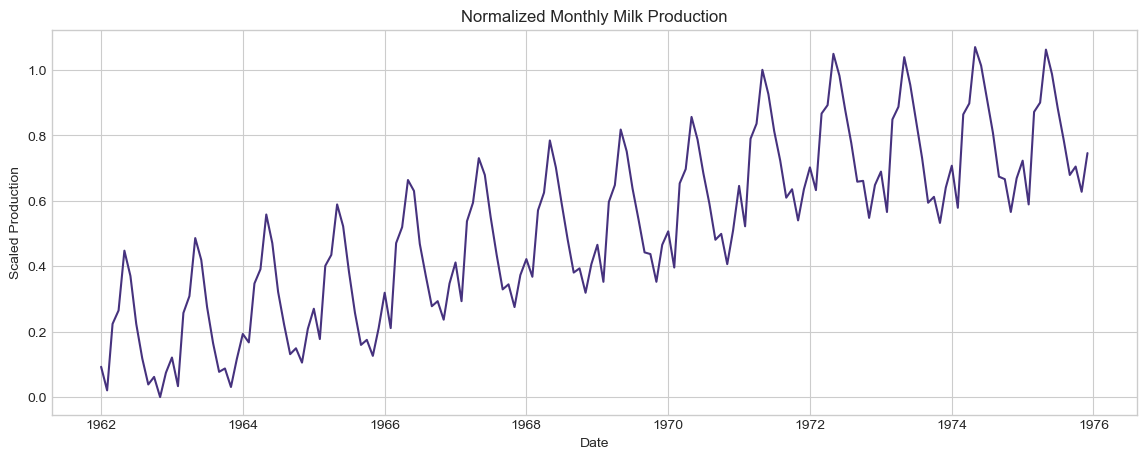

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(
    scaled_df.index,
    scaled_df['Production']
)

plt.title('Normalized Monthly Milk Production')
plt.xlabel('Date')
plt.ylabel('Scaled Production')

plt.show()

Create Time-Series Sequences

In [17]:
# Define window size
WINDOW_SIZE = 12

# Convert scaled data to NumPy array
values = scaled_data.flatten()

# Create sequences
def create_sequences(data, window_size):

    X = []
    y = []
    target_indices = []

    for i in range(window_size, len(data)):

        X.append(data[i-window_size:i])

        y.append(data[i])

        target_indices.append(i)

    return (
        np.array(X),
        np.array(y),
        np.array(target_indices)
    )


# Generate sequences
X, y, target_indices = create_sequences(
    values,
    WINDOW_SIZE
)

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (156, 12)
y Shape: (156,)


Reshape Input Data

In [18]:
# Reshape X
X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

print("Final X Shape:", X.shape)
print("Final y Shape:", y.shape)

Final X Shape: (156, 12, 1)
Final y Shape: (156,)


Split Sequences into Training, Validation and Testing

In [19]:
# Identify target positions
train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

# Training sequences
X_train = X[train_mask]
y_train = y[train_mask]

# Validation sequences
X_val = X[val_mask]
y_val = y[val_mask]

# Testing sequences
X_test = X[test_mask]
y_test = y[test_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (105, 12, 1)
y_train: (105,)
X_val: (25, 12, 1)
y_val: (25,)
X_test: (26, 12, 1)
y_test: (26,)


Verify Data Splitting

In [20]:
print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

print("\nTotal sequences:", len(X_train) + len(X_val) + len(X_test))

Training observations: 105
Validation observations: 25
Testing observations: 26

Total sequences: 156


Build Basic RNN Model

Create RNN Model

In [21]:
# Build RNN model
def build_rnn():

    model = Sequential([

        SimpleRNN(
            32,
            activation='tanh',
            input_shape=(WINDOW_SIZE, 1)
        ),

        Dropout(0.2),

        Dense(16, activation='relu'),

        Dense(1)
    ])

    # Compile model
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model


# Create model
rnn_model = build_rnn()

# Display architecture
rnn_model.summary()

c:\Users\yashr\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)

Train RNN Model

In [22]:
# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True
)

# Train RNN
rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0691 - mae: 0.2128 - val_loss: 0.0156 - val_mae: 0.1023
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0330 - mae: 0.1464 - val_loss: 0.0462 - val_mae: 0.1969
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0250 - mae: 0.1189 - val_loss: 0.0587 - val_mae: 0.2265
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0174 - mae: 0.1051 - val_loss: 0.0115 - val_mae: 0.0957
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0186 - mae: 0.1078 - val_loss: 0.0142 - val_mae: 0.1063
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0134 - mae: 0.0893 - val_loss: 0.0270 - val_mae: 0.1486
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0148 - mae: 0.0895 - val_loss: 0.0097 - val_mae: 0.0842
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0126 - mae: 0.0848 - val_loss: 0.0071 - val_mae: 0.0711
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0084 - mae: 

Plot RNN Training Loss

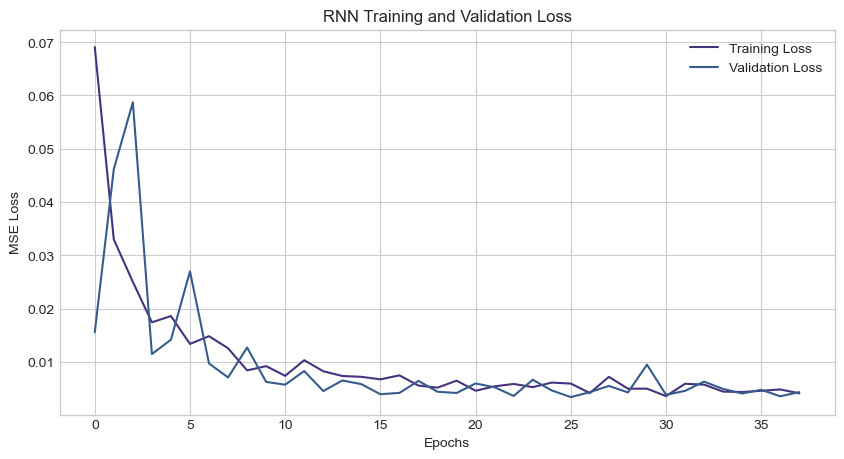

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    rnn_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    rnn_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('RNN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')

plt.legend()
plt.show()

Predict Using RNN

In [24]:
# Predict test data
rnn_predictions_scaled = rnn_model.predict(
    X_test,
    verbose=0
)

# Convert predictions back to original scale
rnn_predictions = scaler.inverse_transform(
    rnn_predictions_scaled
)

# Convert actual values back to original scale
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

print("RNN Predictions:")
print(rnn_predictions[:5])

print("\nActual Values:")
print(y_test_actual[:5])

RNN Predictions:
[[786.01074]
 [809.3252 ]
 [821.97845]
 [817.90515]
 [887.23126]]

Actual Values:
[[760.]
 [802.]
 [828.]
 [778.]
 [889.]]


Build LSTM Model

Create LSTM Model

In [25]:
# Build LSTM model
def build_lstm():

    model = Sequential([

        LSTM(
            32,
            activation='tanh',
            input_shape=(WINDOW_SIZE, 1)
        ),

        Dropout(0.2),

        Dense(16, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model


# Create LSTM model
lstm_model = build_lstm()

# Model summary
lstm_model.summary()

c:\Users\yashr\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.1644 - mae: 0.3503 - val_loss: 0.2622 - val_mae: 0.4870
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0734 - mae: 0.2128 - val_loss: 0.0666 - val_mae: 0.2040
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0375 - mae: 0.1568 - val_loss: 0.0288 - val_mae: 0.1535
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0463 - mae: 0.1813 - val_loss: 0.0264 - val_mae: 0.1419
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0327 - mae: 0.1538 - val_loss: 0.0415 - val_mae: 0.1519
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0335 - mae: 0.1551 - val_loss: 0.0466 - val_mae: 0.1632
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0328 - mae: 0.1506 - val_loss: 0.0358 - val_mae: 0.1427
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0303 - mae: 0.1462 - val_loss: 0.0280 - val_mae: 0.1365
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0337 - mae: 

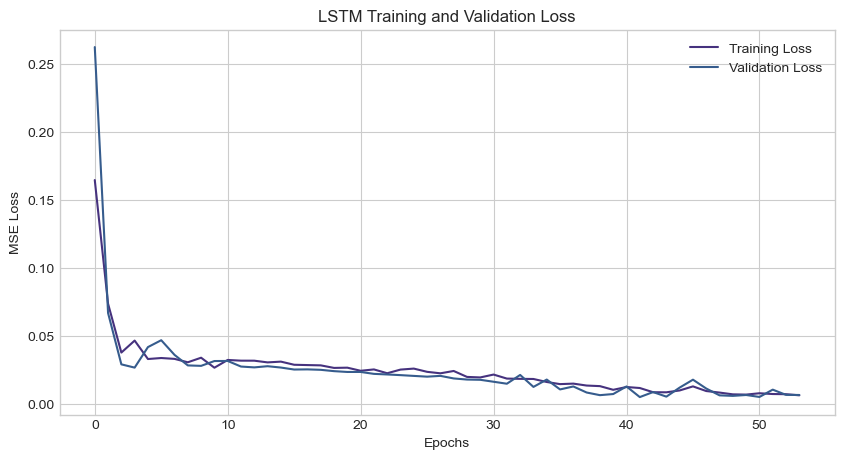

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('LSTM Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')

plt.legend()
plt.show()

In [28]:
# Predict test data
lstm_predictions_scaled = lstm_model.predict(
    X_test,
    verbose=0
)

# Inverse transformation
lstm_predictions = scaler.inverse_transform(
    lstm_predictions_scaled
)

print("LSTM Predictions:")
print(lstm_predictions[:5])

LSTM Predictions:
[[795.5143]
 [805.9207]
 [828.0106]
 [854.9589]
 [887.1613]]


Build GRU Model

Create GRU Model

In [29]:
# Build GRU model
def build_gru():

    model = Sequential([

        GRU(
            32,
            activation='tanh',
            input_shape=(WINDOW_SIZE, 1)
        ),

        Dropout(0.2),

        Dense(16, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model


# Create GRU model
gru_model = build_gru()

# Model summary
gru_model.summary()

c:\Users\yashr\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.1448 - mae: 0.3257 - val_loss: 0.2123 - val_mae: 0.4364
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0666 - mae: 0.2019 - val_loss: 0.0876 - val_mae: 0.2567
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0325 - mae: 0.1445 - val_loss: 0.0314 - val_mae: 0.1356
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0273 - mae: 0.1461 - val_loss: 0.0223 - val_mae: 0.1268
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0288 - mae: 0.1416 - val_loss: 0.0223 - val_mae: 0.1232
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0240 - mae: 0.1315 - val_loss: 0.0266 - val_mae: 0.1261
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0290 - mae: 0.1418 - val_loss: 0.0329 - val_mae: 0.1372
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0237 - mae: 0.1264 - val_loss: 0.0323 - val_mae: 0.1359
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0275 - mae: 

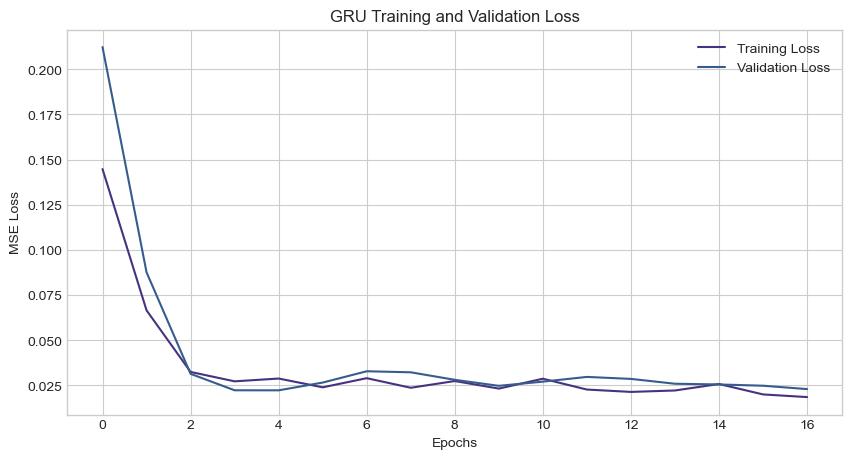

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(
    gru_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    gru_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('GRU Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')

plt.legend()
plt.show()

In [32]:
# Predict test data
gru_predictions_scaled = gru_model.predict(
    X_test,
    verbose=0
)

# Convert predictions into original scale
gru_predictions = scaler.inverse_transform(
    gru_predictions_scaled
)

print("GRU Predictions:")
print(gru_predictions[:5])

GRU Predictions:
[[817.9378 ]
 [801.33453]
 [801.53394]
 [808.09344]
 [800.8415 ]]


Model Evaluation and Performance Comparison

In [34]:
# Evaluation function
def evaluate_model(actual, predicted):

    # Root Mean Squared Error
    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    # Mean Absolute Error
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # Mean Absolute Percentage Error
    mape = np.mean(
        np.abs((actual.flatten() - predicted.flatten()) /
               actual.flatten())
    ) * 100

    return rmse, mae, mape


# Evaluate RNN
rnn_rmse, rnn_mae, rnn_mape = evaluate_model(
    y_test_actual,
    rnn_predictions
)

# Evaluate LSTM
lstm_rmse, lstm_mae, lstm_mape = evaluate_model(
    y_test_actual,
    lstm_predictions
)

# Evaluate GRU
gru_rmse, gru_mae, gru_mape = evaluate_model(
    y_test_actual,
    gru_predictions
)

print("RNN Results:")
print("RMSE:", rnn_rmse)
print("MAE:", rnn_mae)
print("MAPE:", rnn_mape)

print("\nLSTM Results:")
print("RMSE:", lstm_rmse)
print("MAE:", lstm_mae)
print("MAPE:", lstm_mape)

print("\nGRU Results:")
print("RMSE:", gru_rmse)
print("MAE:", gru_mae)
print("MAPE:", gru_mape)

RNN Results:
RMSE: 20.647077833036803
MAE: 16.334294245793277
MAPE: 1.9130808437002698

LSTM Results:
RMSE: 26.74680038826801
MAE: 18.668790377103367
MAPE: 2.2405419195131486

GRU Results:
RMSE: 58.98563079141626
MAE: 48.3253408578726
MAPE: 5.525446490259615


Create Model Comparison DataFrame

In [35]:
# Store model performance
results = pd.DataFrame({

    'Model': ['RNN', 'LSTM', 'GRU'],

    'RMSE': [
        rnn_rmse,
        lstm_rmse,
        gru_rmse
    ],

    'MAE': [
        rnn_mae,
        lstm_mae,
        gru_mae
    ],

    'MAPE': [
        rnn_mape,
        lstm_mape,
        gru_mape
    ]

})

# Display results
display(
    results.sort_values(by='RMSE')
)

,Model,RMSE,MAE,MAPE
0,RNN,20.647078,16.334294,1.913081
1,LSTM,26.746800,18.668790,2.240542
2,GRU,58.985631,48.325341,5.525446


Identify Best Model


In [36]:
# Find best model
best_model_name = results.loc[
    results['RMSE'].idxmin(),
    'Model'
]

print("Best Performing Model:", best_model_name)

Best Performing Model: RNN


Visualize Model Comparison

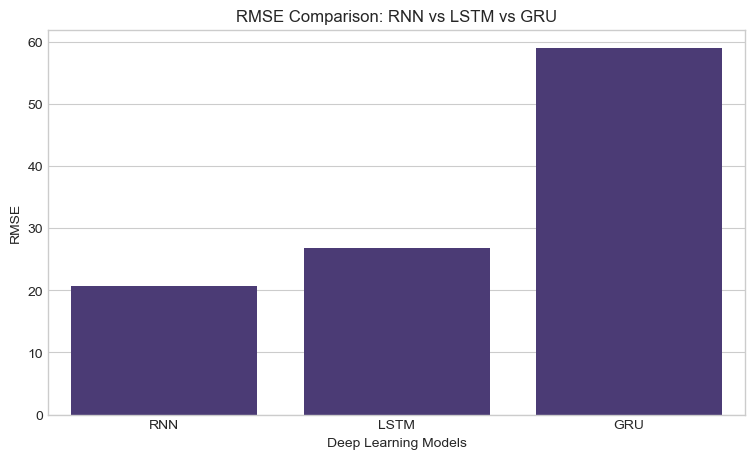

In [37]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='RMSE'
)

plt.title('RMSE Comparison: RNN vs LSTM vs GRU')
plt.xlabel('Deep Learning Models')
plt.ylabel('RMSE')

plt.show()

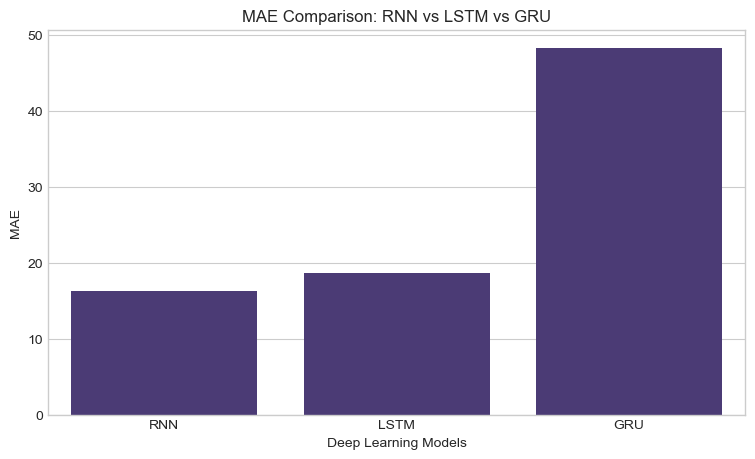

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='MAE'
)

plt.title('MAE Comparison: RNN vs LSTM vs GRU')
plt.xlabel('Deep Learning Models')
plt.ylabel('MAE')

plt.show()

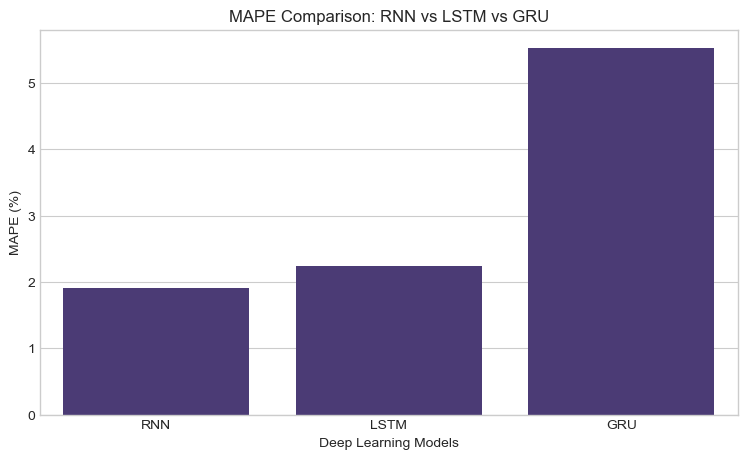

In [39]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='MAPE'
)

plt.title('MAPE Comparison: RNN vs LSTM vs GRU')
plt.xlabel('Deep Learning Models')
plt.ylabel('MAPE (%)')

plt.show()

Actual vs Predicted Values

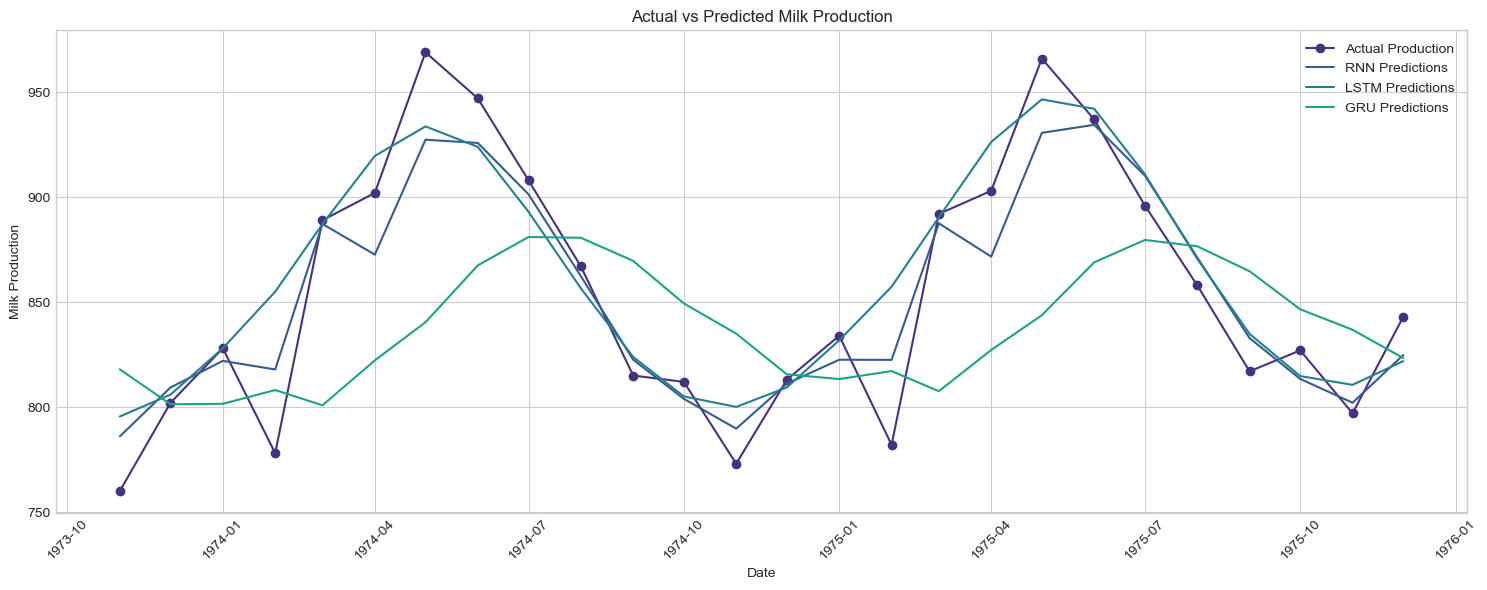

In [40]:
# Actual test dates
test_dates = data.index[target_indices[test_mask]]

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    y_test_actual.flatten(),
    label='Actual Production',
    marker='o'
)

plt.plot(
    test_dates,
    rnn_predictions.flatten(),
    label='RNN Predictions'
)

plt.plot(
    test_dates,
    lstm_predictions.flatten(),
    label='LSTM Predictions'
)

plt.plot(
    test_dates,
    gru_predictions.flatten(),
    label='GRU Predictions'
)

plt.title('Actual vs Predicted Milk Production')
plt.xlabel('Date')
plt.ylabel('Milk Production')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Individual Model Prediction Plots
RNN

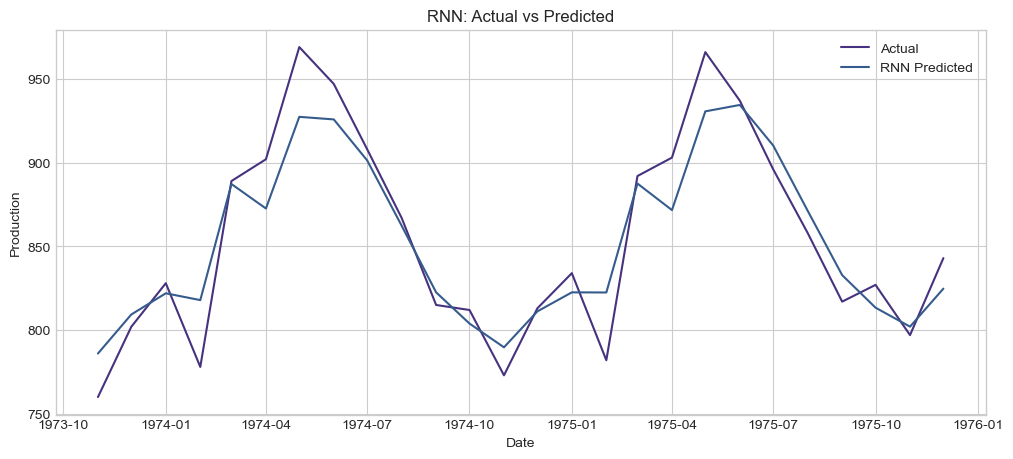

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    y_test_actual.flatten(),
    label='Actual'
)

plt.plot(
    test_dates,
    rnn_predictions.flatten(),
    label='RNN Predicted'
)

plt.title('RNN: Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('Production')

plt.legend()
plt.show()

LSTM

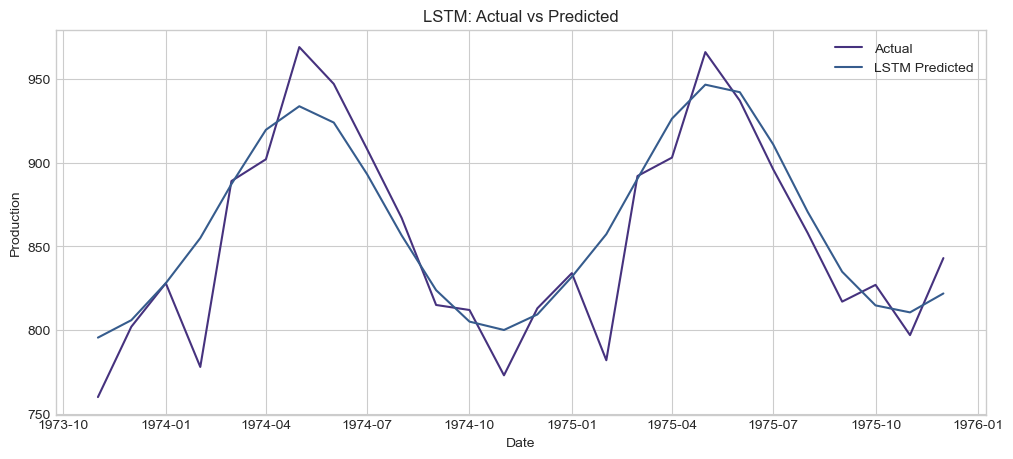

In [42]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    y_test_actual.flatten(),
    label='Actual'
)

plt.plot(
    test_dates,
    lstm_predictions.flatten(),
    label='LSTM Predicted'
)

plt.title('LSTM: Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('Production')

plt.legend()
plt.show()


GRU

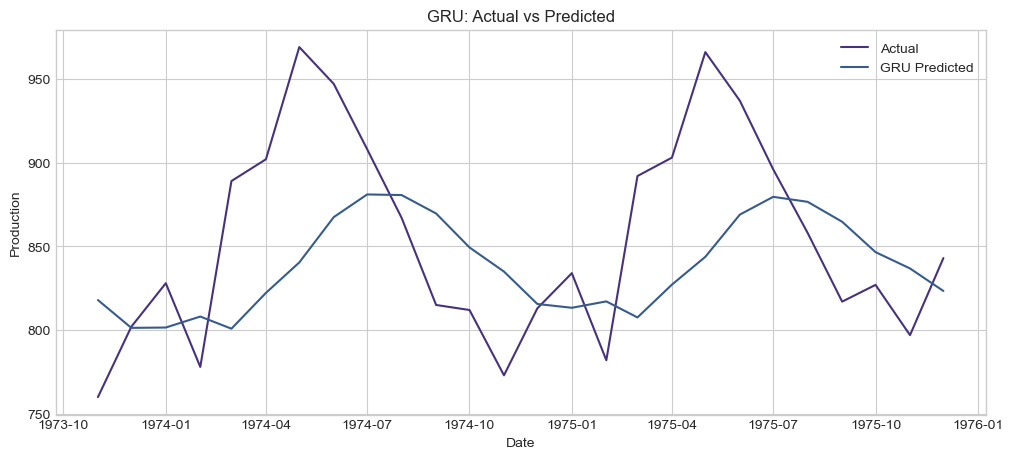

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    y_test_actual.flatten(),
    label='Actual'
)

plt.plot(
    test_dates,
    gru_predictions.flatten(),
    label='GRU Predicted'
)

plt.title('GRU: Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('Production')

plt.legend()
plt.show()

Hyperparameter Tuning

In [44]:
from itertools import product

# Hyperparameter combinations
units_list = [16, 32, 64]
batch_sizes = [8, 16, 32]

tuning_results = []

def build_tuning_model(model_type, units):

    model = Sequential()

    if model_type == 'RNN':

        model.add(
            SimpleRNN(
                units,
                activation='tanh',
                input_shape=(WINDOW_SIZE, 1)
            )
        )

    elif model_type == 'LSTM':

        model.add(
            LSTM(
                units,
                activation='tanh',
                input_shape=(WINDOW_SIZE, 1)
            )
        )

    elif model_type == 'GRU':

        model.add(
            GRU(
                units,
                activation='tanh',
                input_shape=(WINDOW_SIZE, 1)
            )
        )

    model.add(Dense(1))

    model.compile(
        optimizer='adam',
        loss='mse'
    )

    return model


# Test all combinations
for model_type, units, batch_size in product(
    ['RNN', 'LSTM', 'GRU'],
    units_list,
    batch_sizes
):

    print(
        f"Training {model_type}: "
        f"Units={units}, Batch={batch_size}"
    )

    model = build_tuning_model(
        model_type,
        units
    )

    callback = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=100,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=[callback],
        verbose=0
    )

    best_val_loss = min(history.history['val_loss'])

    tuning_results.append({

        'Model': model_type,
        'Units': units,
        'Batch_Size': batch_size,
        'Best_Validation_Loss': best_val_loss

    })


# Display tuning results
tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        by='Best_Validation_Loss'
    )
)

Training RNN: Units=16, Batch=8


c:\Users\yashr\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training RNN: Units=16, Batch=16
Training RNN: Units=16, Batch=32
Training RNN: Units=32, Batch=8
Training RNN: Units=32, Batch=16
Training RNN: Units=32, Batch=32
Training RNN: Units=64, Batch=8
Training RNN: Units=64, Batch=16
Training RNN: Units=64, Batch=32
Training LSTM: Units=16, Batch=8
Training LSTM: Units=16, Batch=16
Training LSTM: Units=16, Batch=32
Training LSTM: Units=32, Batch=8
Training LSTM: Units=32, Batch=16
Training LSTM: Units=32, Batch=32
Training LSTM: Units=64, Batch=8
Training LSTM: Units=64, Batch=16
Training LSTM: Units=64, Batch=32
Training GRU: Units=16, Batch=8
Training GRU: Units=16, Batch=16
Training GRU: Units=16, Batch=32
Training GRU: Units=32, Batch=8
Training GRU: Units=32, Batch=16
Training GRU: Units=32, Batch=32
Training GRU: Units=64, Batch=8
Training GRU: Units=64, Batch=16
Training GRU: Units=64, Batch=32


,Model,Units,Batch_Size,Best_Validation_Loss
3,RNN,32,8,0.002555
4,RNN,32,16,0.002574
6,RNN,64,8,0.002707
8,RNN,64,32,0.002902
7,RNN,64,16,0.003132
0,RNN,16,8,0.003313
17,LSTM,64,32,0.004500
1,RNN,16,16,0.005379
2,RNN,16,32,0.005939
25,GRU,64,16,0.006309


Forecast Milk Production for the Next 12 Months

Select Best Architecture

In [45]:
# Map architecture names to model builders
model_builders = {
    'RNN': build_rnn,
    'LSTM': build_lstm,
    'GRU': build_gru
}

# Select best architecture
final_model = model_builders[best_model_name]()

print("Selected Forecasting Model:", best_model_name)

final_model.summary()

Selected Forecasting Model: RNN


c:\Users\yashr\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_10 (SimpleRNN)       │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)

Prepare Full Historical Data

In [46]:
# Create sequences using all available observations
X_full, y_full, full_indices = create_sequences(
    scaled_data.flatten(),
    WINDOW_SIZE
)

# Reshape for deep learning
X_full = X_full.reshape(
    X_full.shape[0],
    X_full.shape[1],
    1
)

print("Full X Shape:", X_full.shape)
print("Full y Shape:", y_full.shape)

Full X Shape: (156, 12, 1)
Full y Shape: (156,)


Train Final Model

In [47]:
# Train selected model on all historical sequences
final_history = final_model.fit(
    X_full,
    y_full,
    epochs=50,
    batch_size=16,
    verbose=1
)

print("Final model training completed!")

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3779 - mae: 0.5275
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0858 - mae: 0.2356 
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0551 - mae: 0.1905 
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0400 - mae: 0.1613 
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0361 - mae: 0.1559 
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0344 - mae: 0.1451 
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0230 - mae: 0.1210 
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0243 - mae: 0.1217 
Epoch 9/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0242 - mae: 0.1206 
Epoch 10/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0194 - mae: 0.1120 
Epoch 11/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0191 - mae: 0.1122 
Epoch 12/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0197 - mae: 0.1098 
Epoch 13/50
10/10 ━━━━━━━━━━━━━━━━━━━━

Recursive Forecasting

In [48]:
# Last 12 months of scaled data
current_window = scaled_data[-WINDOW_SIZE:].reshape(
    1,
    WINDOW_SIZE,
    1
)

# Store future predictions
future_predictions_scaled = []

# Forecast next 12 months
for month in range(12):

    # Predict next month
    prediction = final_model.predict(
        current_window,
        verbose=0
    )[0, 0]

    # Save prediction
    future_predictions_scaled.append(prediction)

    # Update window
    current_window = np.concatenate(
        [
            current_window[:, 1:, :],
            np.array(prediction).reshape(1, 1, 1)
        ],
        axis=1
    )


# Convert predictions into original scale
future_predictions = scaler.inverse_transform(
    np.array(future_predictions_scaled).reshape(-1, 1)
)

print("Next 12 Months Forecast:")
print(future_predictions.flatten())

Next 12 Months Forecast:
[833.54016 817.1253  873.2842  876.58685 927.853   907.339   890.22015
 865.5842  829.8401  829.5884  805.56934 836.0487 ]


Create Future Dates

In [49]:
# Generate next 12 monthly dates
future_dates = pd.date_range(
    start=data.index[-1] + MonthBegin(1),
    periods=12,
    freq='MS'
)

# Create forecast DataFrame
forecast_df = pd.DataFrame({

    'Date': future_dates,

    'Predicted_Production': future_predictions.flatten()

})

# Display forecast
display(forecast_df)

,Date,Predicted_Production
0,1976-01-01,833.540161
1,1976-02-01,817.125305
2,1976-03-01,873.284180
3,1976-04-01,876.586853
4,1976-05-01,927.853027
5,1976-06-01,907.338989
6,1976-07-01,890.220154
7,1976-08-01,865.584229
8,1976-09-01,829.840088
9,1976-10-01,829.588379


Visualize Next 12 Months Forecast

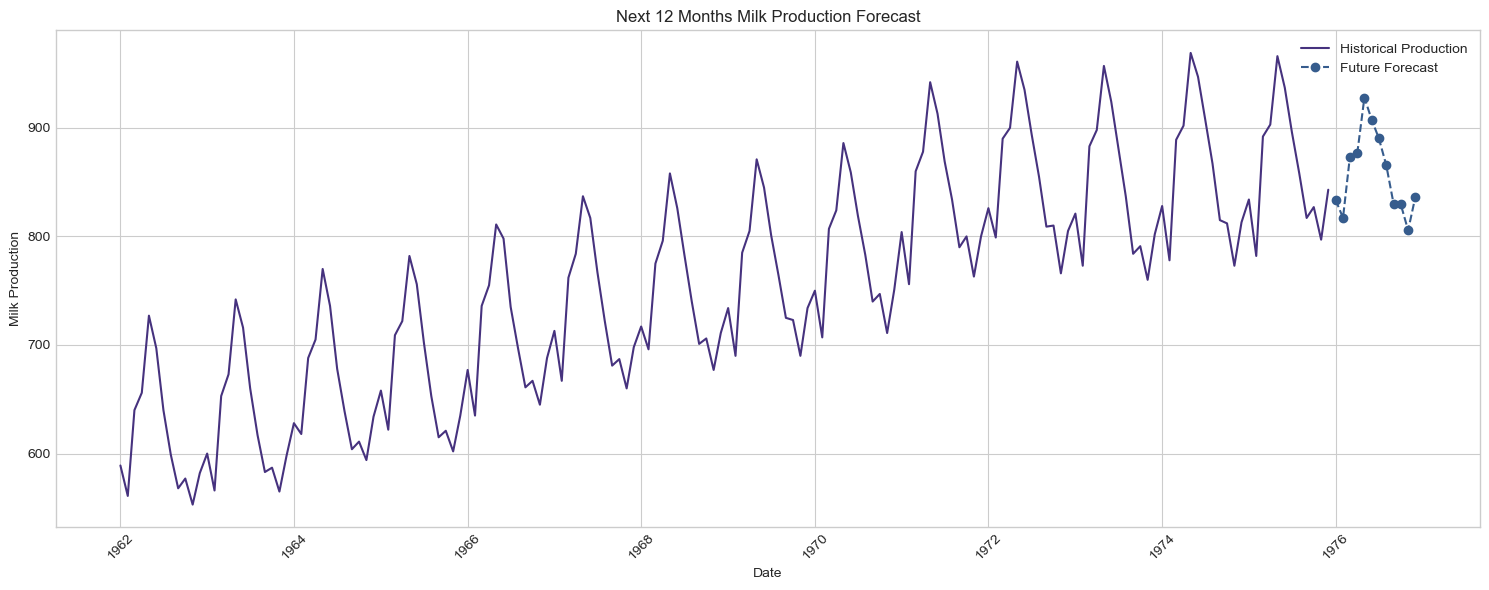

In [50]:
plt.figure(figsize=(15, 6))

# Historical production
plt.plot(
    data.index,
    data['Production'],
    label='Historical Production'
)

# Future predictions
plt.plot(
    forecast_df['Date'],
    forecast_df['Predicted_Production'],
    label='Future Forecast',
    marker='o',
    linestyle='--'
)

plt.title('Next 12 Months Milk Production Forecast')
plt.xlabel('Date')
plt.ylabel('Milk Production')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Calculate Approximate Intervals

In [51]:
# Get RMSE of selected model
best_rmse = results.loc[
    results['Model'] == best_model_name,
    'RMSE'
].iloc[0]

# Forecast horizon
horizon = np.arange(1, 13)

# Approximate uncertainty
uncertainty = 1.96 * best_rmse * np.sqrt(horizon)

# Calculate lower and upper limits
forecast_df['Lower_Bound'] = (
    forecast_df['Predicted_Production'] - uncertainty
)

forecast_df['Upper_Bound'] = (
    forecast_df['Predicted_Production'] + uncertainty
)

# Display final forecast
display(forecast_df)

,Date,Predicted_Production,Lower_Bound,Upper_Bound
0,1976-01-01,833.540161,793.071889,874.008434
1,1976-02-01,817.125305,759.894525,874.356085
2,1976-03-01,873.284180,803.191076,943.377284
3,1976-04-01,876.586853,795.650308,957.523398
4,1976-05-01,927.853027,837.363219,1018.342836
5,1976-06-01,907.338989,808.212371,1006.465608
6,1976-07-01,890.220154,783.151169,997.289139
7,1976-08-01,865.584229,751.122669,980.045788
8,1976-09-01,829.840088,708.435270,951.244906
9,1976-10-01,829.588379,701.616465,957.560293


Visualize Forecast with Uncertainty

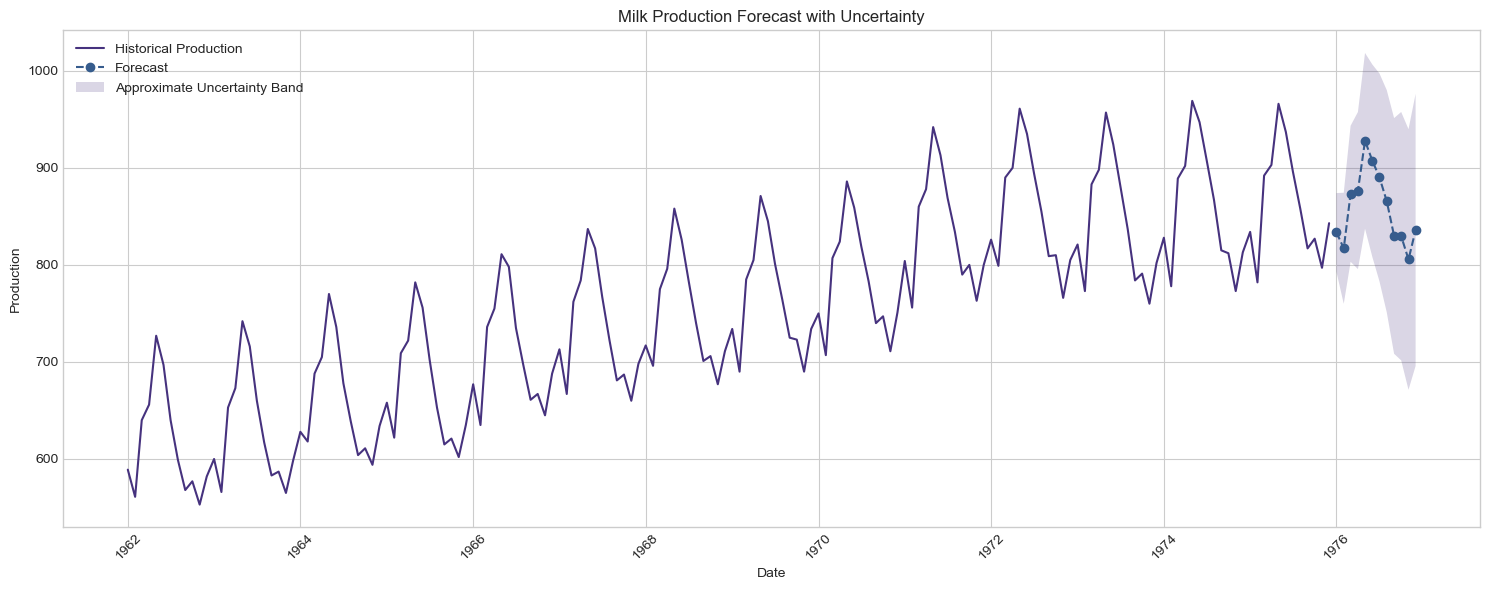

In [52]:
plt.figure(figsize=(15, 6))

# Historical data
plt.plot(
    data.index,
    data['Production'],
    label='Historical Production'
)

# Forecast
plt.plot(
    forecast_df['Date'],
    forecast_df['Predicted_Production'],
    marker='o',
    linestyle='--',
    label='Forecast'
)

# Uncertainty interval
plt.fill_between(
    forecast_df['Date'],
    forecast_df['Lower_Bound'],
    forecast_df['Upper_Bound'],
    alpha=0.2,
    label='Approximate Uncertainty Band'
)

plt.title('Milk Production Forecast with Uncertainty')
plt.xlabel('Date')
plt.ylabel('Production')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Final Model Performance Report

In [53]:
# Create final comparison
final_results = results.copy()

# Rank models based on RMSE
final_results['Rank'] = (
    final_results['RMSE'].rank(method='min')
)

final_results = final_results.sort_values(
    by='RMSE'
)

display(final_results)

print("Best Model:", best_model_name)
print("Best RMSE:", best_rmse)

,Model,RMSE,MAE,MAPE,Rank
0,RNN,20.647078,16.334294,1.913081,1.0
1,LSTM,26.746800,18.668790,2.240542,2.0
2,GRU,58.985631,48.325341,5.525446,3.0


Best Model: RNN
Best RMSE: 20.647077833036803


Export Results to CSV

In [54]:
# Export model comparison
final_results.to_csv(
    'milk_production_model_comparison.csv',
    index=False
)

# Export 12-month forecast
forecast_df.to_csv(
    'milk_production_forecast.csv',
    index=False
)

print("Results exported successfully!")

Results exported successfully!
